 02_visualization_vllm — plots from processed vLLM benchmark outputs

In [26]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)

ROOT = Path.cwd().resolve().parents[0] if Path.cwd().name == "notebooks" else Path.cwd().resolve()
PROCESSED_DIR = ROOT / "results" / "processed"
FIGURES_DIR = ROOT / "docs" / "figures" / "vllm"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

summary_path = PROCESSED_DIR / "summary_vllm.csv"
samples_path = PROCESSED_DIR / "samples_vllm.csv"
ranking_accuracy_path = PROCESSED_DIR / "ranking_accuracy_vllm.csv"
ranking_efficiency_path = PROCESSED_DIR / "ranking_efficiency_vllm.csv"

summary = pd.read_csv(summary_path)
samples = pd.read_csv(samples_path)
ranking_accuracy = pd.read_csv(ranking_accuracy_path)
ranking_efficiency = pd.read_csv(ranking_efficiency_path)

print("summary:", summary.shape)
print("samples:", samples.shape)
print("ranking_accuracy:", ranking_accuracy.shape)
print("ranking_efficiency:", ranking_efficiency.shape)


summary: (38, 46)
samples: (31700, 41)
ranking_accuracy: (9, 19)
ranking_efficiency: (9, 19)


 Quick inspection

In [27]:
display(summary.head())
display(samples.head())
display(ranking_accuracy.head())


,backend,run_id,dataset,model_alias_dir,source_path,model,repo_id,served_model_id,accuracy,accuracy_sd,ttft,ttft_sd,latency,latency_sd,tps,tps_sd,cpu,cpu_sd,cpu_peak,ram_used_mb_peak,ram,temp_c_avg,temp_c_avg_sd,temp_c_peak,gpu,gpu_sd,gpu_peak,vram,power,power_sd,power_peak,sustained_tps,sustained_tps_sd,sustained_sps,sustained_sps_sd,latency_s,ttft_s,ttft_share_of_latency,tps_per_ram,tps_per_vram,tps_per_watt,sustained_tps_per_vram,accuracy_per_latency,accuracy_per_ram,accuracy_per_vram,accuracy_per_watt
0,vllm,2026-03-31_15-55-49,mmlu,gemma3_4b_w4a16,/home/stephane/resource-efficiency-benchmark/r...,gemma3_4b_w4a16,RedHatAI/gemma-3-4b-it-quantized.w4a16,Qwen/Qwen2.5-1.5B-Instruct,0.52,0.0,71.9428,0.9192,127.9508,1.5443,18.2306,0.2049,7.4985,1.5035,65.0,14813.18,1019.99,70.0537,1.8942,79.500,12.8890,11.3311,29.0,6869.0,60.7467,0.7789,64.53,5.5996,0.0661,5.4898,0.0648,0.127951,0.071943,0.562269,0.017873,0.002654,0.300108,0.000815,0.004064,0.000510,0.000076,0.008560
1,vllm,2026-03-31_15-55-49,hellaswag,gemma3_4b_w4a16,/home/stephane/resource-efficiency-benchmark/r...,gemma3_4b_w4a16,RedHatAI/gemma-3-4b-it-quantized.w4a16,Qwen/Qwen2.5-1.5B-Instruct,0.26,0.0,70.8052,1.7534,124.9218,3.0983,18.5055,0.4667,7.0284,0.6785,61.0,12489.36,1020.02,69.5761,0.6263,71.625,11.2297,14.2129,34.0,6802.0,61.1533,0.1697,63.91,5.6406,0.1397,5.6406,0.1397,0.124922,0.070805,0.566796,0.018142,0.002721,0.302608,0.000829,0.002081,0.000255,0.000038,0.004252
2,vllm,2026-03-31_15-55-49,gsm8k,gemma3_4b_w4a16,/home/stephane/resource-efficiency-benchmark/r...,gemma3_4b_w4a16,RedHatAI/gemma-3-4b-it-quantized.w4a16,Qwen/Qwen2.5-1.5B-Instruct,0.03,0.0,71.8905,0.5932,151.7749,0.9190,44.4205,0.1135,7.4114,0.0777,29.3,8649.20,1020.02,72.2063,0.2803,74.250,32.8930,11.2241,100.0,6107.0,101.1637,1.2629,130.21,22.2931,0.2932,4.5871,0.0603,0.151775,0.071890,0.473665,0.043549,0.007274,0.439095,0.003650,0.000198,0.000029,0.000005,0.000297
3,vllm,2026-04-02_03-43-28,dolly,gemma3_4b_w4a16,/home/stephane/resource-efficiency-benchmark/r...,gemma3_4b_w4a16,RedHatAI/gemma-3-4b-it-quantized.w4a16,iqbalamo93/Phi-4-mini-instruct-GPTQ-4bit,NaN,NaN,89.8702,16.4796,623.5248,48.2390,87.6739,6.5252,8.9205,2.7985,44.1,10372.47,1192.01,72.6397,1.0871,75.375,55.9527,35.2792,100.0,4780.0,166.9069,5.0177,192.33,70.3371,6.0829,1.4846,0.1025,0.623525,0.089870,0.144133,0.073551,0.018342,0.525286,0.014715,NaN,NaN,NaN,NaN
4,vllm,2026-03-31_15-55-49,mmlu,granite4_htiny_awq,/home/stephane/resource-efficiency-benchmark/r...,granite4_htiny_awq,cyankiwi/granite-4.0-h-tiny-AWQ-4bit,Qwen/Qwen2.5-1.5B-Instruct,0.52,0.0,68.4738,0.2988,120.6718,0.4516,19.5530,0.0631,6.4220,0.0346,27.3,8697.27,1021.79,69.8841,0.4322,71.500,16.7760,13.7400,30.0,6197.0,62.6146,1.0045,66.89,5.9502,0.0212,5.8335,0.0208,0.120672,0.068474,0.567438,0.019136,0.003155,0.312275,0.000960,0.004309,0.000509,0.000084,0.008305


,repo_id,served_model_id,model,dataset_name,run_idx,sample_idx,prompt,question,choices,instruction,context,gold_answer,parsed_prediction,correct,raw_output,output_tokens,ttft_ms,latency_ms,tokens_per_sec,cpu_percent_avg,cpu_percent_peak,ram_used_mb_peak,process_ram_mb_peak,temp_c_avg,temp_c_peak,gpu_percent_avg,gpu_percent_peak,vram_used_mb_peak,power_w_avg,power_w_peak,model_alias_dir,run_id,dataset,source_path,backend,latency_s,ttft_s,ttft_share_of_latency,tokens_per_ram,tokens_per_vram,tokens_per_watt
0,RedHatAI/gemma-3-4b-it-quantized.w4a16,Qwen/Qwen2.5-1.5B-Instruct,gemma3_4b_w4a16,mmlu,1,1,"In primates, the location of which of the foll...","In primates, the location of which of the foll...",the feet || the skull || the foramen magnum ||...,NaN,NaN,2.0,C,True,C. the foramen,3,128.2590,191.7984,47.2148,11.2000,14.1,14080.68,1019.95,74.2083,74.250,0.0,0.0,6709.0,51.7133,52.39,gemma3_4b_w4a16,2026-03-31_15-55-49,mmlu,/home/stephane/resource-efficiency-benchmark/r...,vllm,0.191798,0.128259,0.668718,0.046291,0.007038,0.913011
1,RedHatAI/gemma-3-4b-it-quantized.w4a16,Qwen/Qwen2.5-1.5B-Instruct,gemma3_4b_w4a16,mmlu,1,2,In the comic strip 'Peanuts' what is Schroeder...,In the comic strip 'Peanuts' what is Schroeder...,Dancing || playing football || playing the pia...,NaN,NaN,2.0,C,True,C,1,79.7790,142.9208,15.8374,11.5667,12.6,14111.52,1019.95,74.3750,74.375,0.0,0.0,6709.0,54.2967,55.04,gemma3_4b_w4a16,2026-03-31_15-55-49,mmlu,/home/stephane/resource-efficiency-benchmark/r...,vllm,0.142921,0.079779,0.558204,0.015528,0.002361,0.291683
2,RedHatAI/gemma-3-4b-it-quantized.w4a16,Qwen/Qwen2.5-1.5B-Instruct,gemma3_4b_w4a16,mmlu,1,3,The Yang-shao culture gave way to the Lung-Sha...,The Yang-shao culture gave way to the Lung-Sha...,"6,000 B.P. || 5,000 B.P. || 4,000 B.P. || 3,00...",NaN,NaN,1.0,C,False,C,1,81.9868,147.3174,15.3068,28.0000,57.5,14117.65,1019.95,74.3750,74.375,0.0,0.0,6709.0,56.6300,57.48,gemma3_4b_w4a16,2026-03-31_15-55-49,mmlu,/home/stephane/resource-efficiency-benchmark/r...,vllm,0.147317,0.081987,0.556532,0.015007,0.002282,0.270295
3,RedHatAI/gemma-3-4b-it-quantized.w4a16,Qwen/Qwen2.5-1.5B-Instruct,gemma3_4b_w4a16,mmlu,1,4,At which of the following locations does bile ...,At which of the following locations does bile ...,Gastroesophageal sphincter || Duodenum || Ileo...,NaN,NaN,1.0,B,True,B,1,79.4288,143.5314,15.6000,27.2667,56.4,14123.26,1019.95,74.5417,74.625,0.0,0.0,6709.0,58.5467,59.84,gemma3_4b_w4a16,2026-03-31_15-55-49,mmlu,/home/stephane/resource-efficiency-benchmark/r...,vllm,0.143531,0.079429,0.553390,0.015295,0.002325,0.266454
4,RedHatAI/gemma-3-4b-it-quantized.w4a16,Qwen/Qwen2.5-1.5B-Instruct,gemma3_4b_w4a16,mmlu,1,5,"Let A be a finite set with m elements, and let...","Let A be a finite set with m elements, and let...",n^m || n!/(n - m)! || n! || n!/(m!(n - m)!),NaN,NaN,0.0,A,True,A,1,82.5121,146.4888,15.6307,11.5333,13.2,14127.28,1019.95,74.6250,74.625,0.0,0.0,6709.0,60.6300,62.17,gemma3_4b_w4a16,2026-03-31_15-55-49,mmlu,/home/stephane/resource-efficiency-benchmark/r...,vllm,0.146489,0.082512,0.563266,0.015325,0.002330,0.257805


,backend,model,n_runs,n_datasets,avg_accuracy,avg_ttft_ms,avg_latency_ms,avg_tps,avg_sustained_tps,avg_cpu,avg_ram_mb,avg_gpu,avg_vram_mb,avg_power_w,avg_tps_per_vram,avg_tps_per_watt,avg_accuracy_per_latency,avg_accuracy_per_vram,avg_accuracy_per_watt
0,vllm,phi4mini_gptq_4bit,1,3,0.27,72.752167,137.666833,26.416900,10.943933,7.186167,1016.476667,15.277333,6664.333333,66.823900,0.003957,0.382358,0.002094,0.000041,0.004294
1,vllm,granite4_htiny_awq,1,3,0.27,69.667400,131.040900,27.734200,11.344933,6.732467,1021.813333,20.150333,6195.666667,75.213667,0.004477,0.354035,0.002219,0.000044,0.004274
2,vllm,qwen2_7b_q4,1,3,0.27,69.679700,131.080133,27.722433,11.343367,6.745267,1021.683333,15.415233,6194.000000,75.208600,0.004476,0.353915,0.002219,0.000044,0.004271
3,vllm,ministral3_8b_awq,1,3,0.27,69.826467,131.393633,27.648500,11.310733,6.758667,1021.966667,16.514900,6210.000000,75.030700,0.004445,0.353840,0.002211,0.000044,0.004287
4,vllm,qwen2_5_1_5b,1,3,0.27,69.573967,130.966800,27.727800,11.369767,6.735733,1021.236667,17.233767,6196.000000,75.293800,0.004476,0.353518,0.002219,0.000044,0.004277


 Split scored / dolly

In [28]:
scored = summary[summary["dataset"].isin(["mmlu", "hellaswag", "gsm8k"])].copy()
dolly = summary[summary["dataset"] == "dolly"].copy()

print("scored:", scored.shape)
print("dolly:", dolly.shape)


scored: (27, 46)
dolly: (11, 46)


 Average accuracy by model

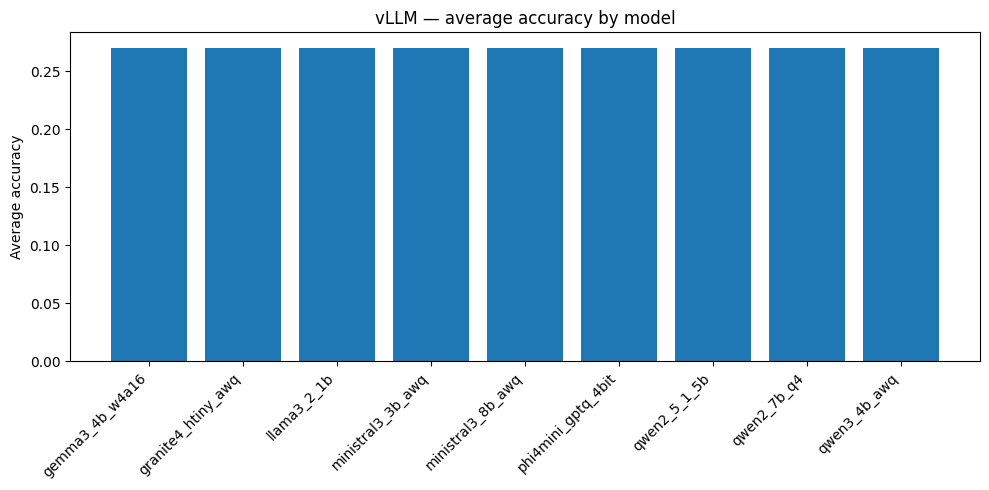

In [29]:
acc_plot = (
    scored.groupby("model", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 5))
plt.bar(acc_plot["model"], acc_plot["accuracy"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Average accuracy")
plt.title("vLLM — average accuracy by model")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "accuracy_by_model.png", dpi=200)
plt.show()


 Average latency by model

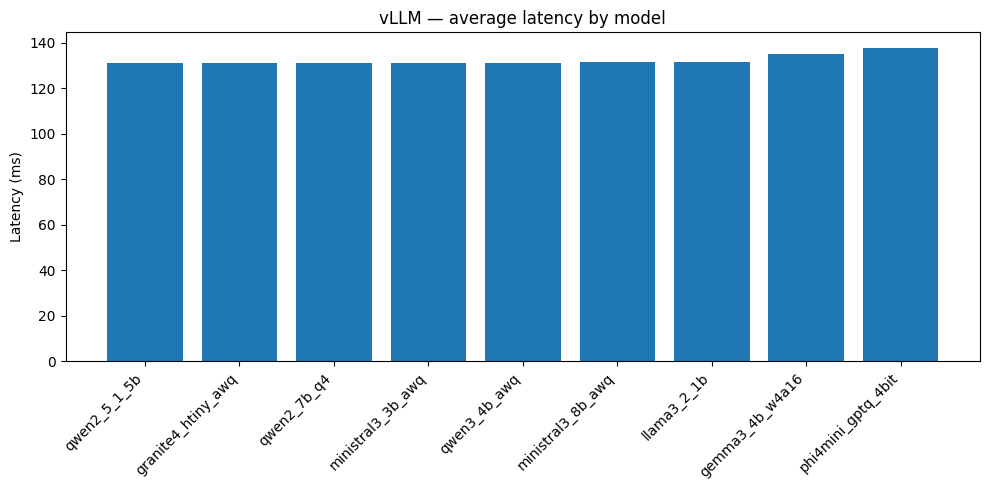

In [30]:
lat_plot = (
    scored.groupby("model", as_index=False)["latency"]
    .mean()
    .sort_values("latency", ascending=True)
)

plt.figure(figsize=(10, 5))
plt.bar(lat_plot["model"], lat_plot["latency"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Latency (ms)")
plt.title("vLLM — average latency by model")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "latency_by_model.png", dpi=200)
plt.show()


 Throughput by model

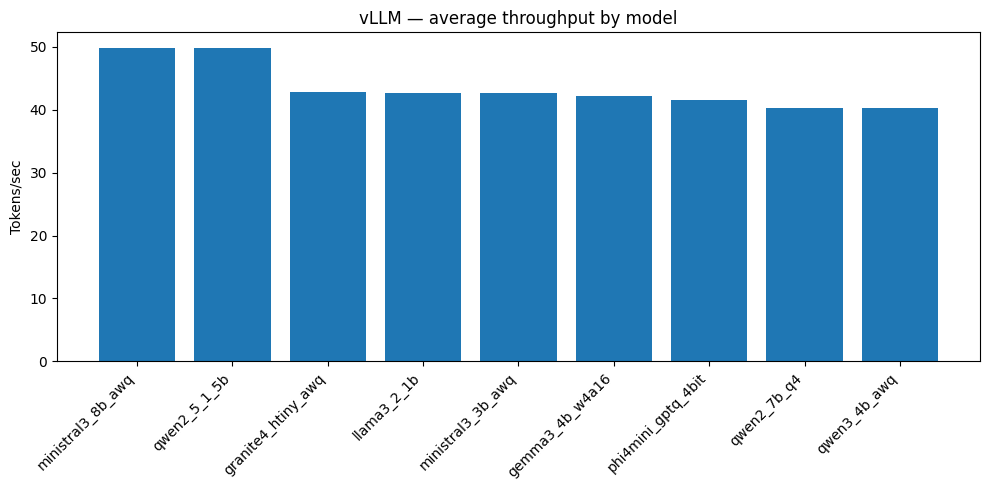

In [31]:
tps_plot = (
    summary.groupby("model", as_index=False)["tps"]
    .mean()
    .sort_values("tps", ascending=False)
)

plt.figure(figsize=(10, 5))
plt.bar(tps_plot["model"], tps_plot["tps"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Tokens/sec")
plt.title("vLLM — average throughput by model")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "throughput_by_model.png", dpi=200)
plt.show()


 GPU utilization by model

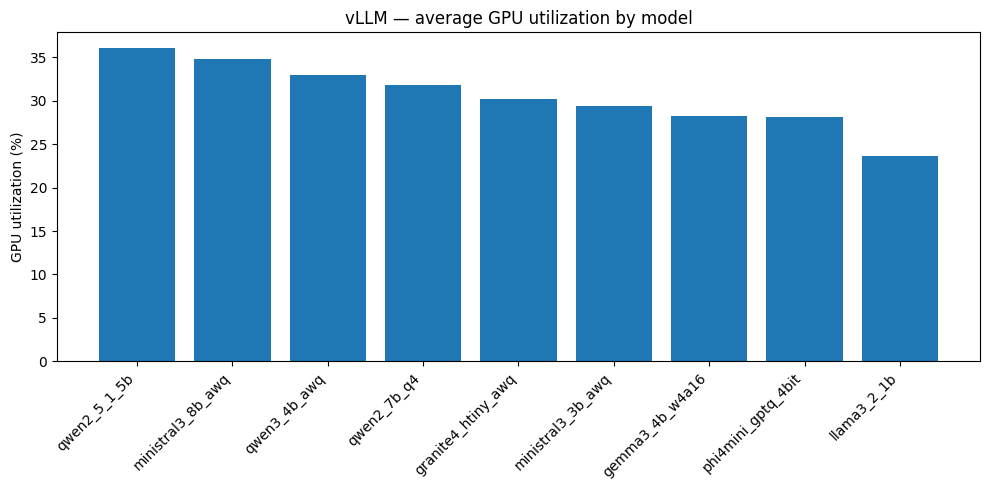

In [32]:
gpu_plot = (
    summary.groupby("model", as_index=False)["gpu"]
    .mean()
    .sort_values("gpu", ascending=False)
)

plt.figure(figsize=(10, 5))
plt.bar(gpu_plot["model"], gpu_plot["gpu"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("GPU utilization (%)")
plt.title("vLLM — average GPU utilization by model")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "gpu_by_model.png", dpi=200)
plt.show()


 VRAM usage by model

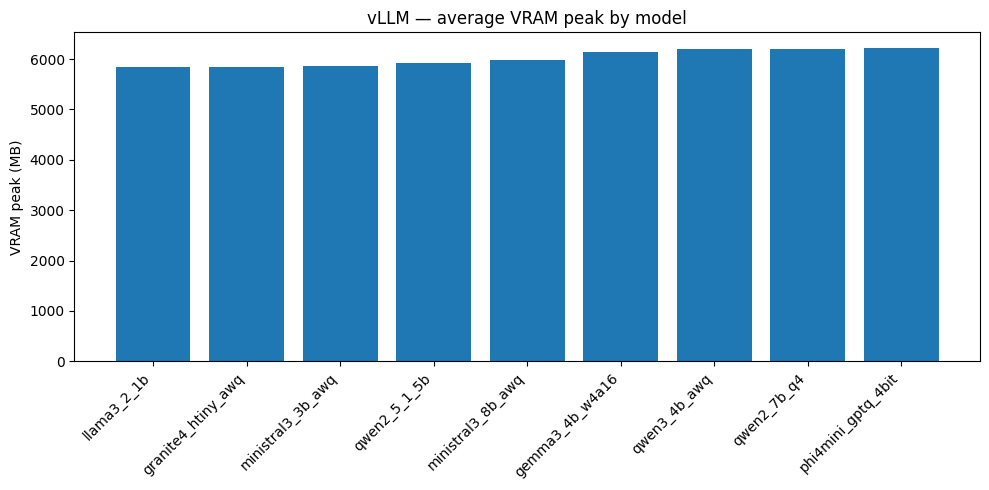

In [33]:
vram_plot = (
    summary.groupby("model", as_index=False)["vram"]
    .mean()
    .sort_values("vram", ascending=True)
)

plt.figure(figsize=(10, 5))
plt.bar(vram_plot["model"], vram_plot["vram"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("VRAM peak (MB)")
plt.title("vLLM — average VRAM peak by model")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "vram_by_model.png", dpi=200)
plt.show()


 Power draw by model

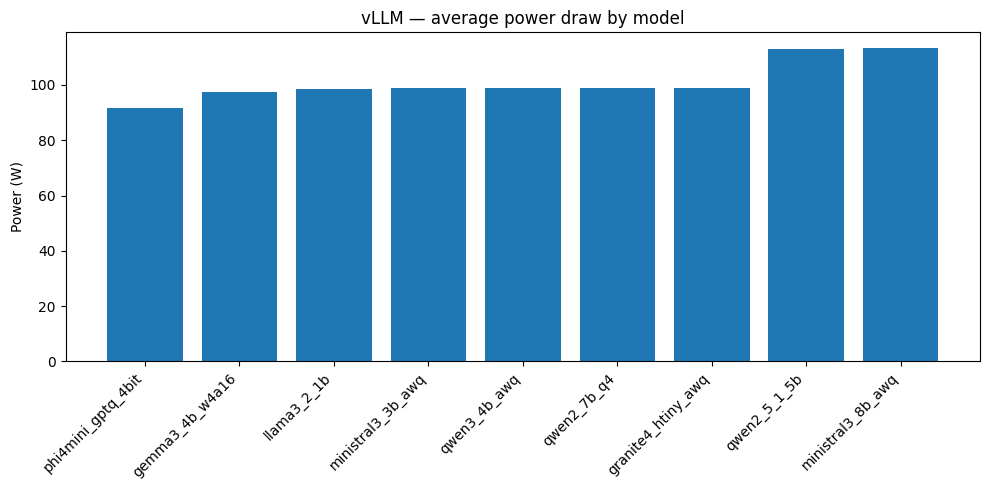

In [34]:
power_plot = (
    summary.groupby("model", as_index=False)["power"]
    .mean()
    .sort_values("power", ascending=True)
)

plt.figure(figsize=(10, 5))
plt.bar(power_plot["model"], power_plot["power"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Power (W)")
plt.title("vLLM — average power draw by model")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "power_by_model.png", dpi=200)
plt.show()


 Tokens/sec per watt by model

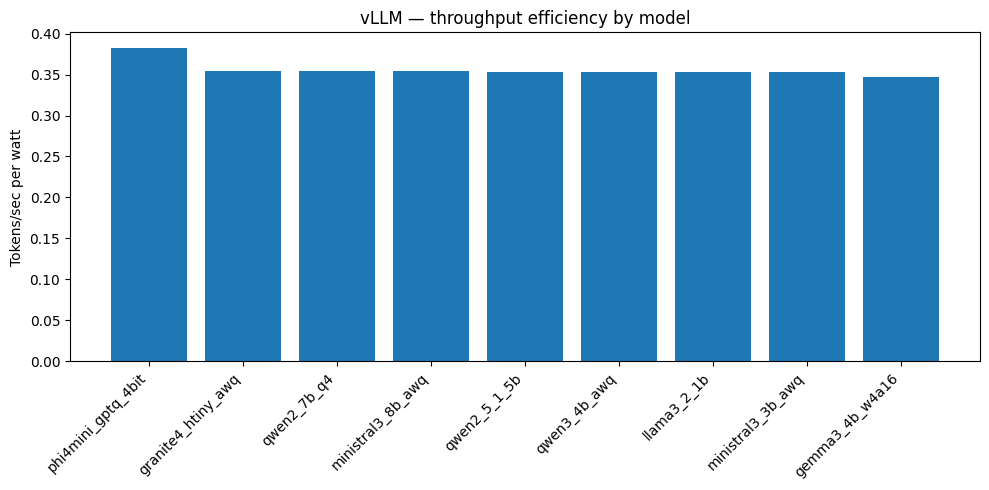

In [35]:
eff_plot = (
    scored.groupby("model", as_index=False)["tps_per_watt"]
    .mean()
    .sort_values("tps_per_watt", ascending=False)
)

plt.figure(figsize=(10, 5))
plt.bar(eff_plot["model"], eff_plot["tps_per_watt"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Tokens/sec per watt")
plt.title("vLLM — throughput efficiency by model")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tps_per_watt_by_model.png", dpi=200)
plt.show()


 Accuracy vs latency

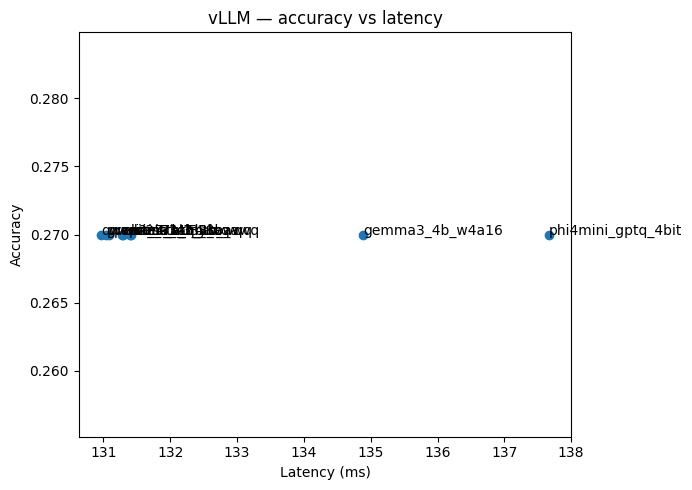

In [36]:
acc_lat = (
    scored.groupby("model", as_index=False)
    .agg({"accuracy": "mean", "latency": "mean"})
)

plt.figure(figsize=(7, 5))
plt.scatter(acc_lat["latency"], acc_lat["accuracy"])

for _, row in acc_lat.iterrows():
    plt.annotate(row["model"], (row["latency"], row["accuracy"]))

plt.xlabel("Latency (ms)")
plt.ylabel("Accuracy")
plt.title("vLLM — accuracy vs latency")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "accuracy_vs_latency.png", dpi=200)
plt.show()


 Accuracy vs power

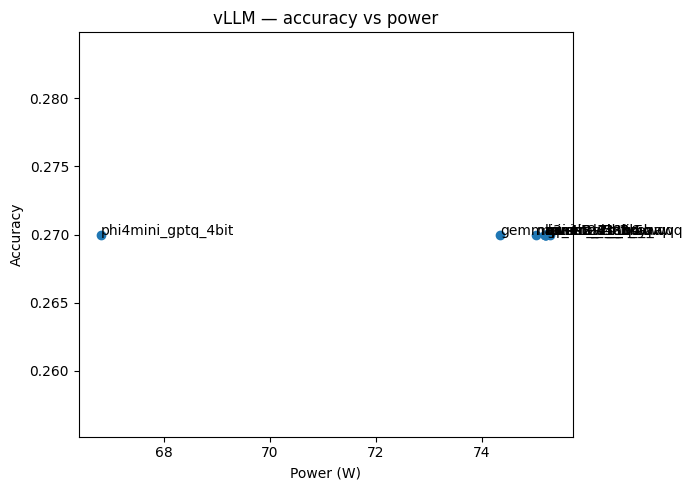

In [37]:
acc_power = (
    scored.groupby("model", as_index=False)
    .agg({"accuracy": "mean", "power": "mean"})
)

plt.figure(figsize=(7, 5))
plt.scatter(acc_power["power"], acc_power["accuracy"])

for _, row in acc_power.iterrows():
    plt.annotate(row["model"], (row["power"], row["accuracy"]))

plt.xlabel("Power (W)")
plt.ylabel("Accuracy")
plt.title("vLLM — accuracy vs power")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "accuracy_vs_power.png", dpi=200)
plt.show()


 Throughput vs VRAM

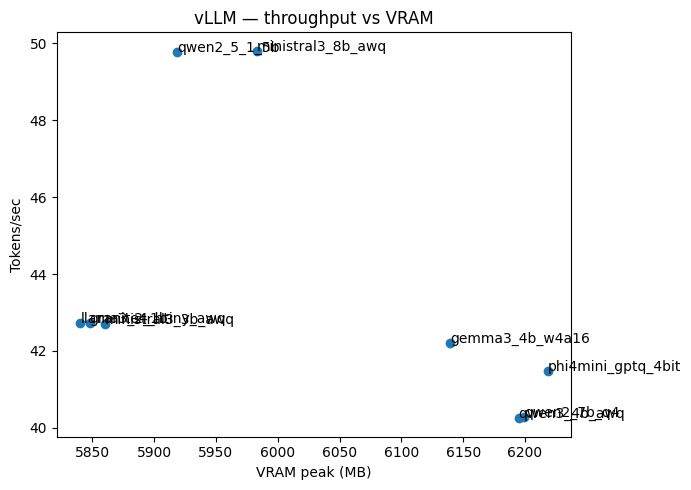

In [38]:
tps_vram = (
    summary.groupby("model", as_index=False)
    .agg({"tps": "mean", "vram": "mean"})
)

plt.figure(figsize=(7, 5))
plt.scatter(tps_vram["vram"], tps_vram["tps"])

for _, row in tps_vram.iterrows():
    plt.annotate(row["model"], (row["vram"], row["tps"]))

plt.xlabel("VRAM peak (MB)")
plt.ylabel("Tokens/sec")
plt.title("vLLM — throughput vs VRAM")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "throughput_vs_vram.png", dpi=200)
plt.show()


 Throughput vs power

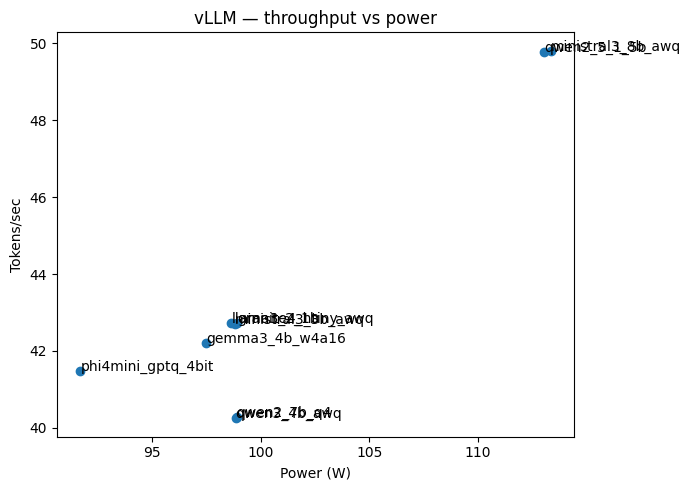

In [39]:
tps_power = (
    summary.groupby("model", as_index=False)
    .agg({"tps": "mean", "power": "mean"})
)

plt.figure(figsize=(7, 5))
plt.scatter(tps_power["power"], tps_power["tps"])

for _, row in tps_power.iterrows():
    plt.annotate(row["model"], (row["power"], row["tps"]))

plt.xlabel("Power (W)")
plt.ylabel("Tokens/sec")
plt.title("vLLM — throughput vs power")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "throughput_vs_power.png", dpi=200)
plt.show()


 Accuracy vs VRAM

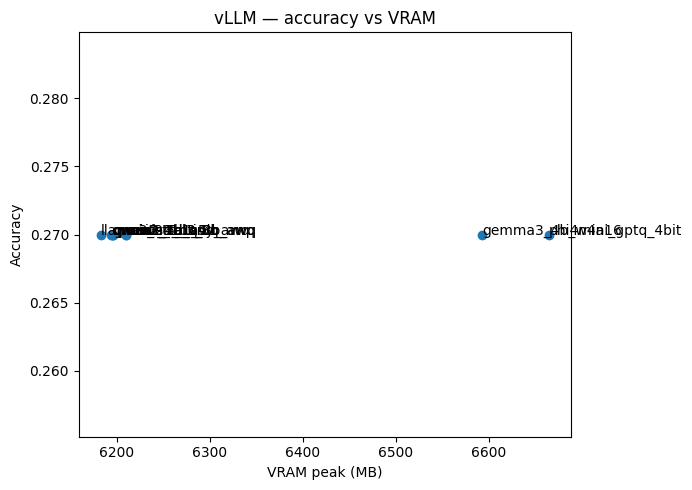

In [40]:
acc_vram = (
    scored.groupby("model", as_index=False)
    .agg({"accuracy": "mean", "vram": "mean"})
)

plt.figure(figsize=(7, 5))
plt.scatter(acc_vram["vram"], acc_vram["accuracy"])

for _, row in acc_vram.iterrows():
    plt.annotate(row["model"], (row["vram"], row["accuracy"]))

plt.xlabel("VRAM peak (MB)")
plt.ylabel("Accuracy")
plt.title("vLLM — accuracy vs VRAM")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "accuracy_vs_vram.png", dpi=200)
plt.show()


 Per-dataset accuracy

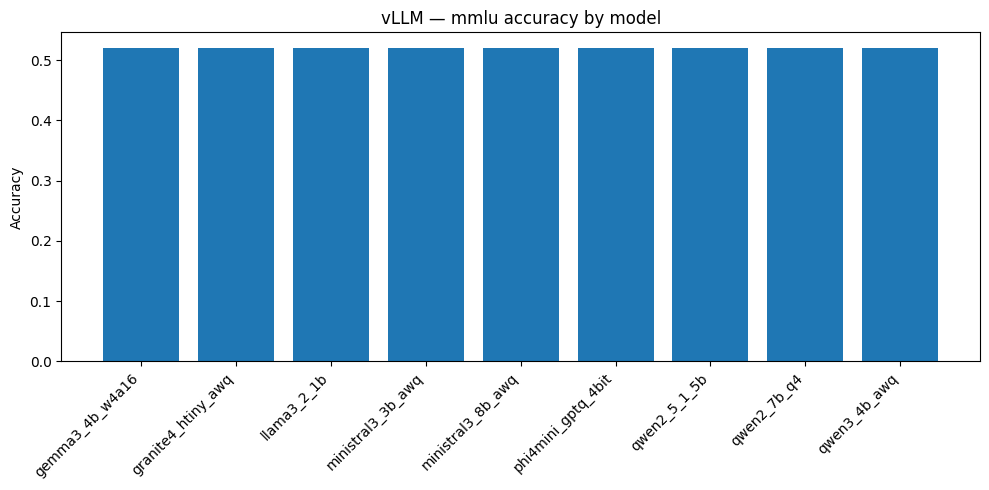

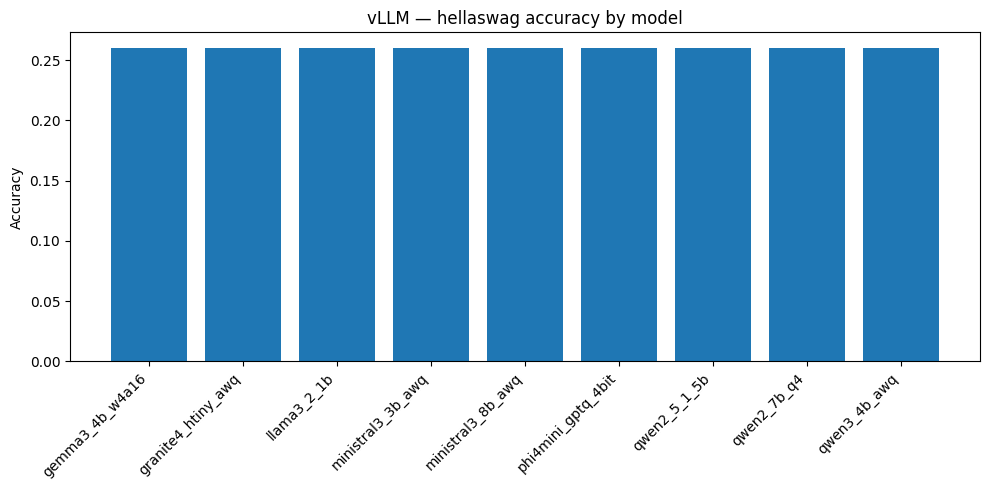

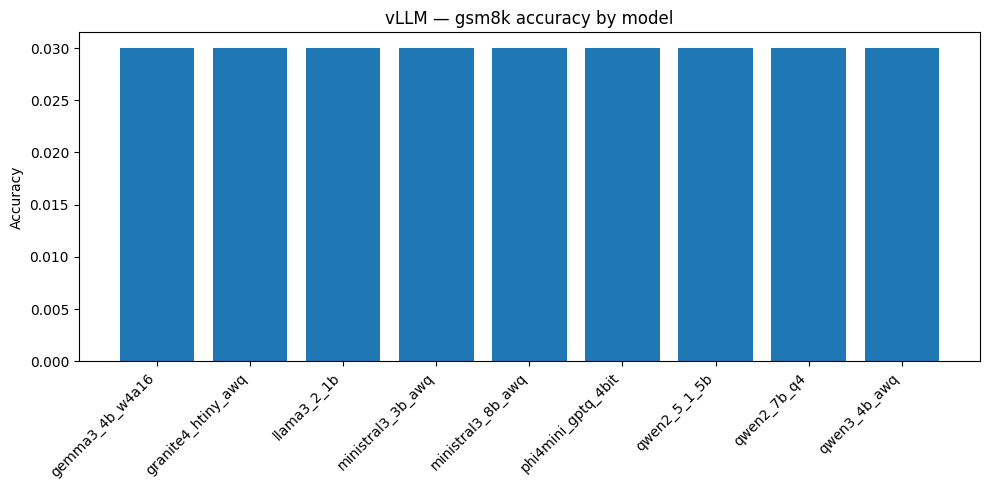

In [41]:
for ds in ["mmlu", "hellaswag", "gsm8k"]:
    sub = (
        scored[scored["dataset"] == ds]
        .groupby("model", as_index=False)["accuracy"]
        .mean()
        .sort_values("accuracy", ascending=False)
    )

    plt.figure(figsize=(10, 5))
    plt.bar(sub["model"], sub["accuracy"])
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Accuracy")
    plt.title(f"vLLM — {ds} accuracy by model")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{ds}_accuracy_by_model.png", dpi=200)
    plt.show()


 Per-dataset latency

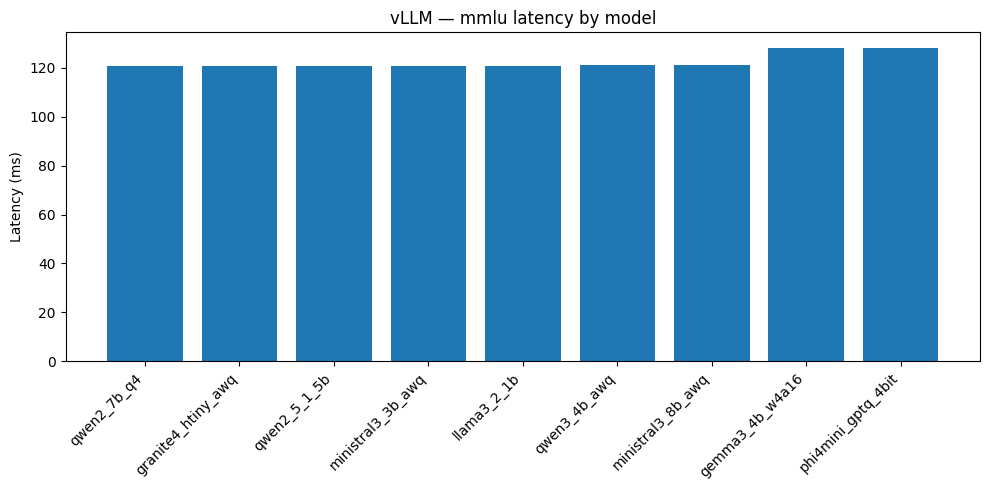

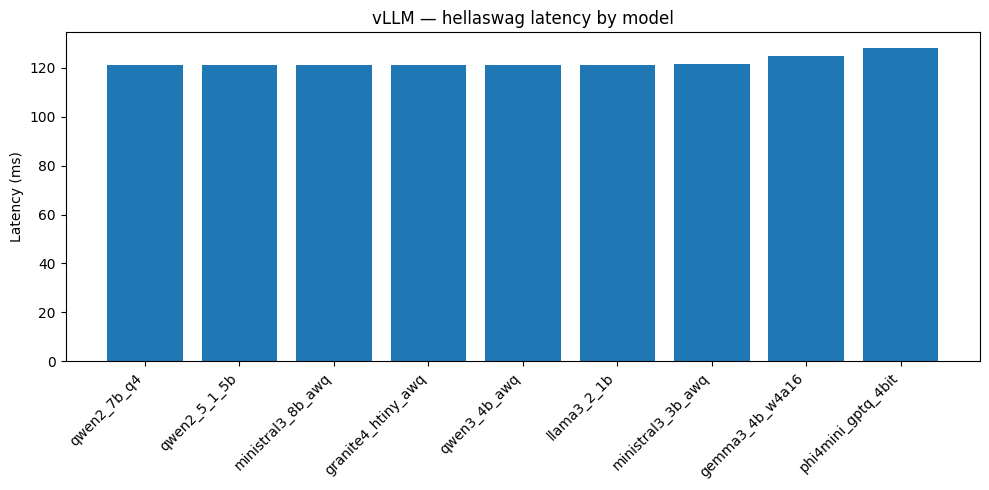

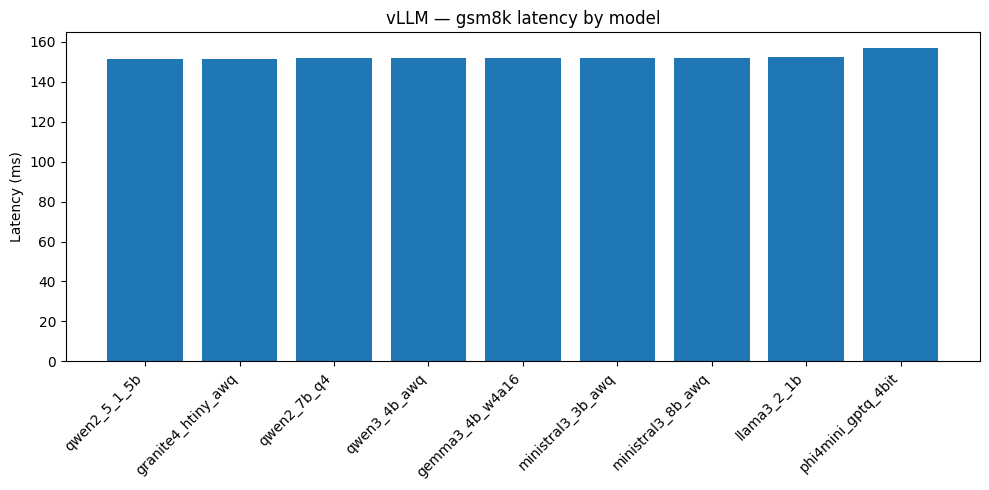

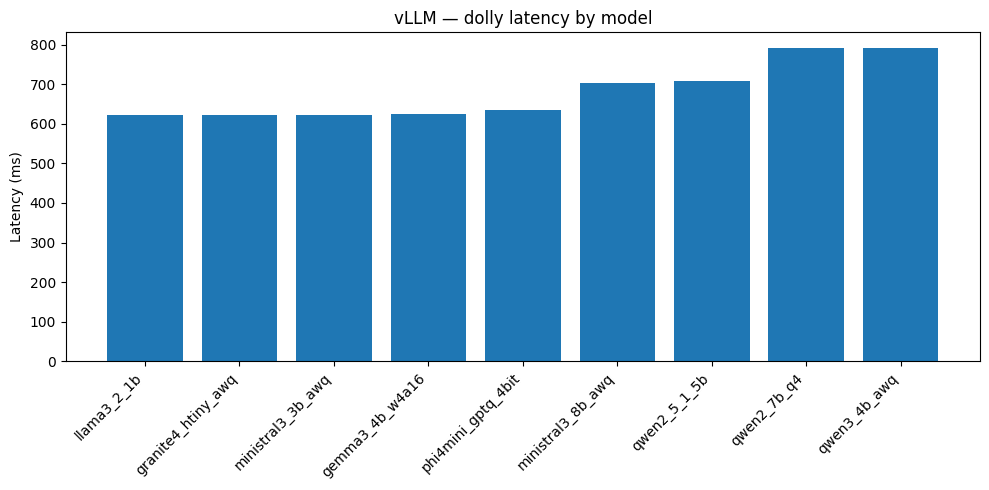

In [42]:
for ds in ["mmlu", "hellaswag", "gsm8k", "dolly"]:
    sub = (
        summary[summary["dataset"] == ds]
        .groupby("model", as_index=False)["latency"]
        .mean()
        .sort_values("latency", ascending=True)
    )

    plt.figure(figsize=(10, 5))
    plt.bar(sub["model"], sub["latency"])
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Latency (ms)")
    plt.title(f"vLLM — {ds} latency by model")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{ds}_latency_by_model.png", dpi=200)
    plt.show()


 Dolly throughput

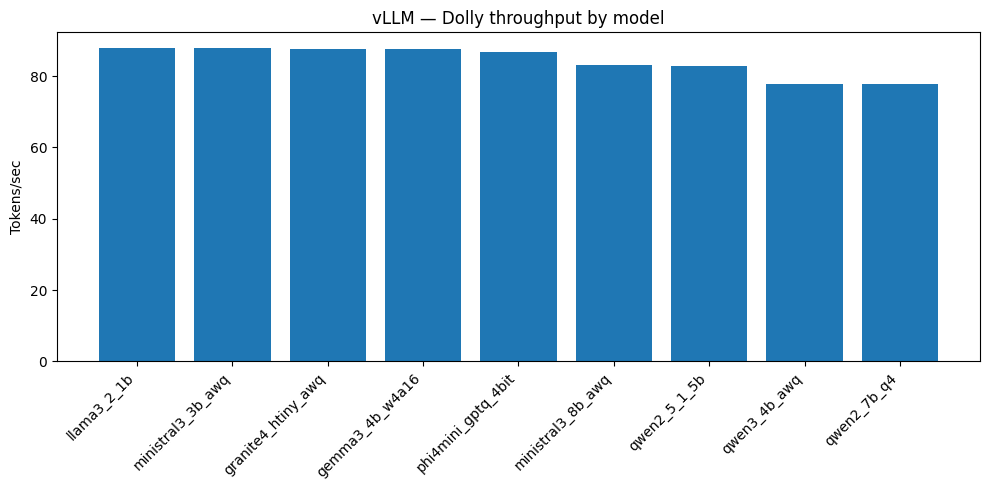

In [43]:
if not dolly.empty:
    dolly_tps = (
        dolly.groupby("model", as_index=False)["tps"]
        .mean()
        .sort_values("tps", ascending=False)
    )

    plt.figure(figsize=(10, 5))
    plt.bar(dolly_tps["model"], dolly_tps["tps"])
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Tokens/sec")
    plt.title("vLLM — Dolly throughput by model")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "dolly_throughput_by_model.png", dpi=200)
    plt.show()


 Sample latency distribution by model

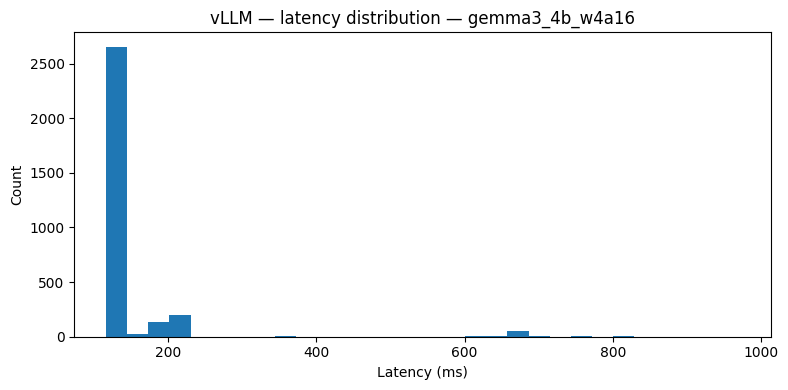

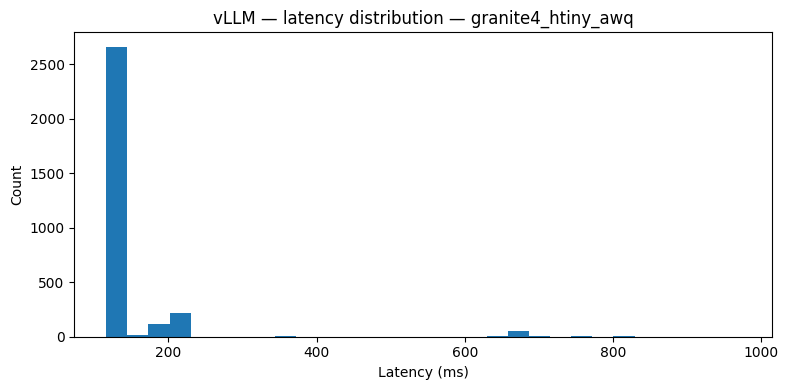

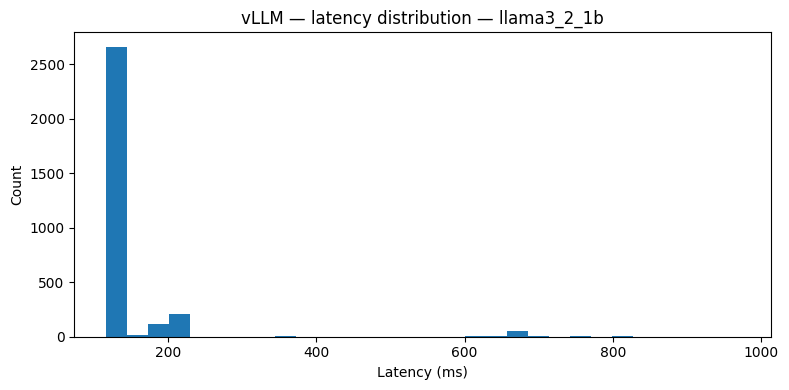

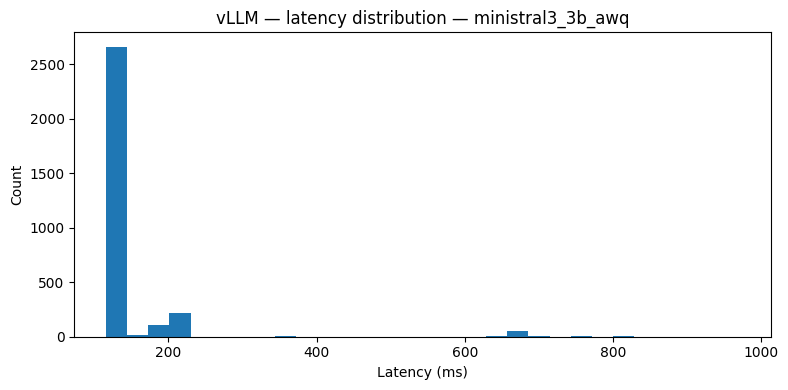

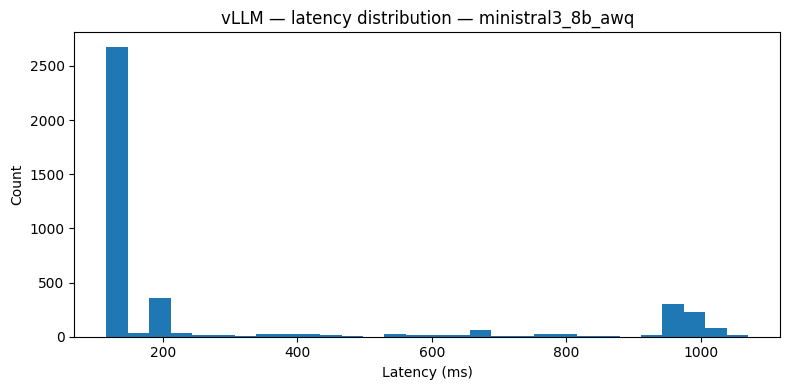

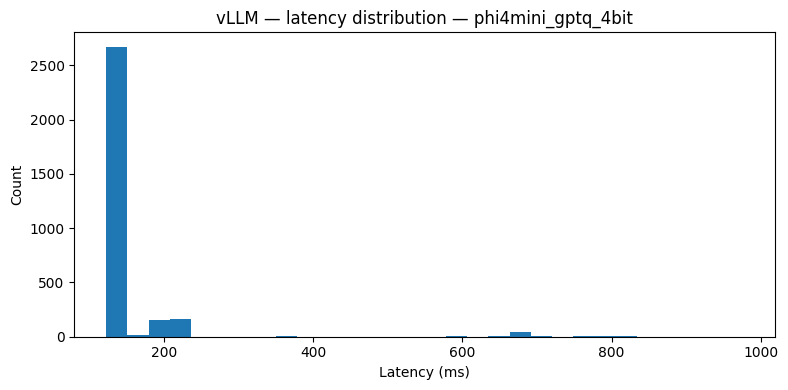

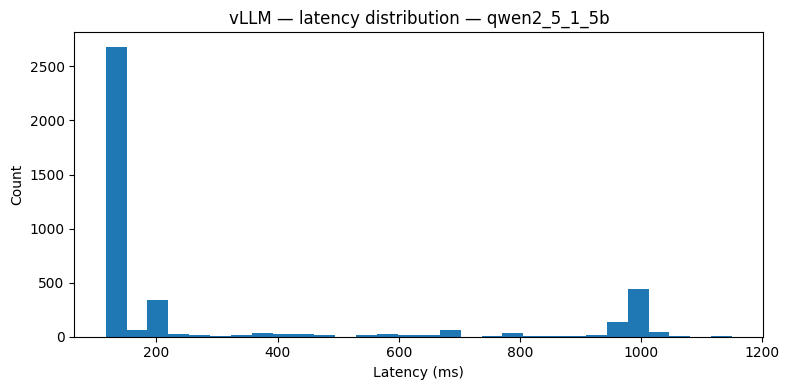

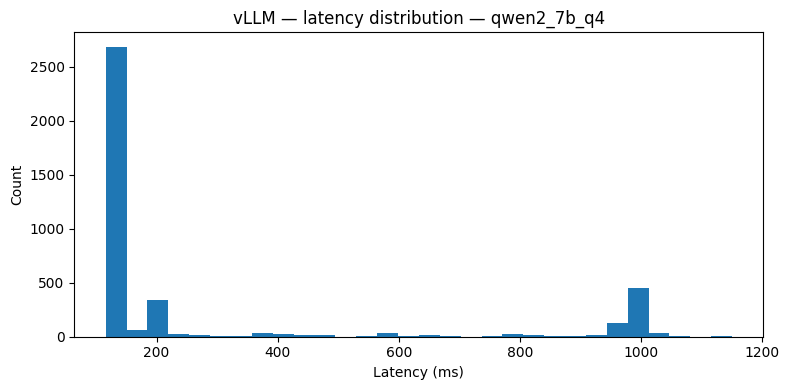

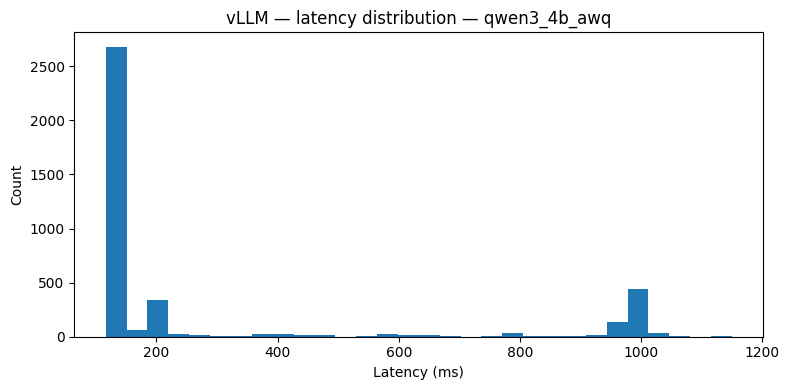

In [44]:
if "latency_ms" in samples.columns:
    for model_name in sorted(samples["model"].dropna().unique()):
        sub = samples[samples["model"] == model_name]["latency_ms"].dropna()

        plt.figure(figsize=(8, 4))
        plt.hist(sub, bins=30)
        plt.xlabel("Latency (ms)")
        plt.ylabel("Count")
        plt.title(f"vLLM — latency distribution — {model_name}")
        plt.tight_layout()
        safe_name = str(model_name).replace("/", "_")
        plt.savefig(FIGURES_DIR / f"latency_distribution_{safe_name}.png", dpi=200)
        plt.show()


 Sample tokens/sec distribution by model

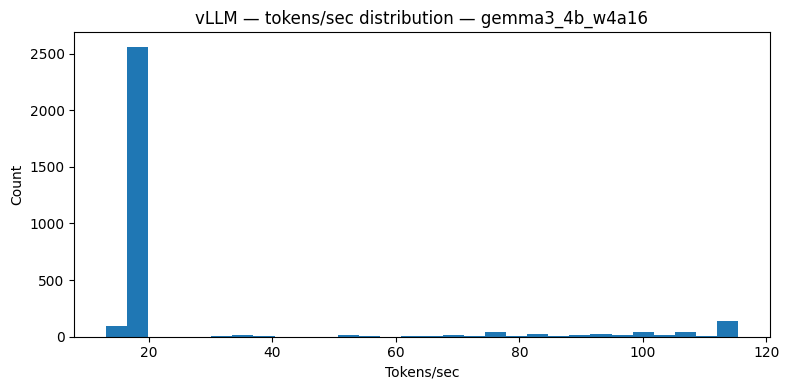

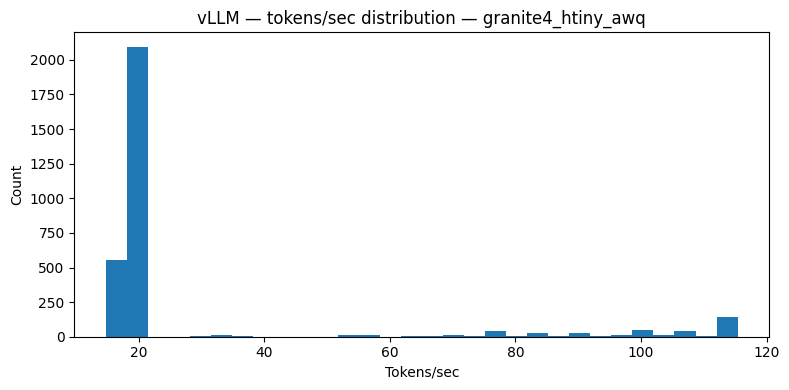

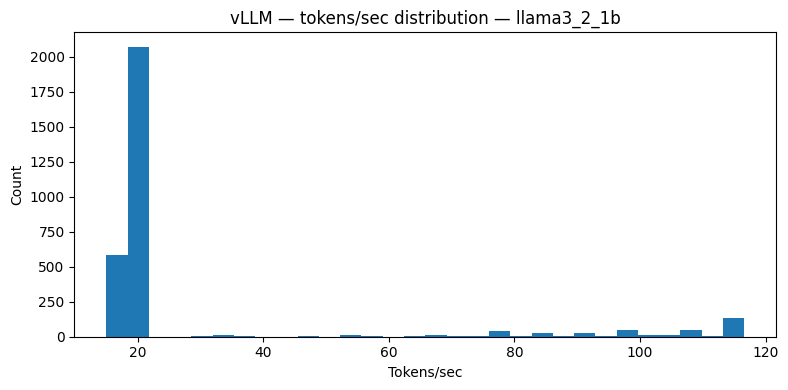

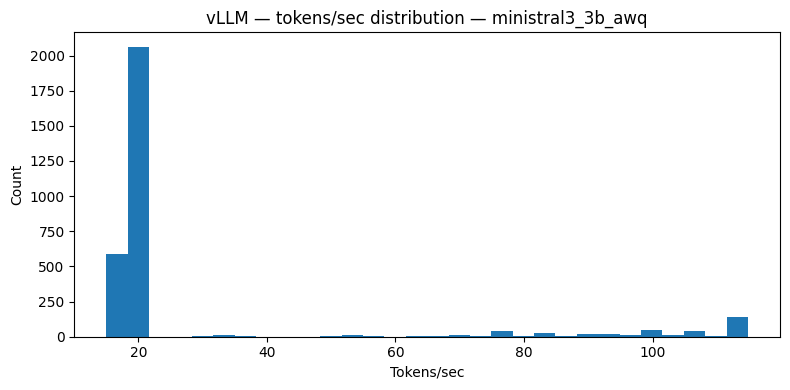

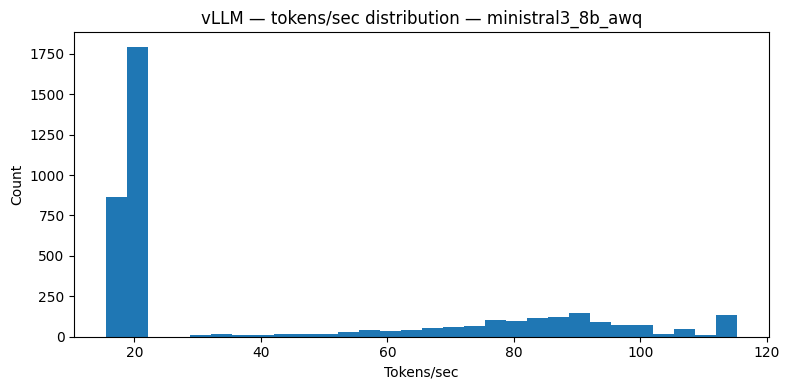

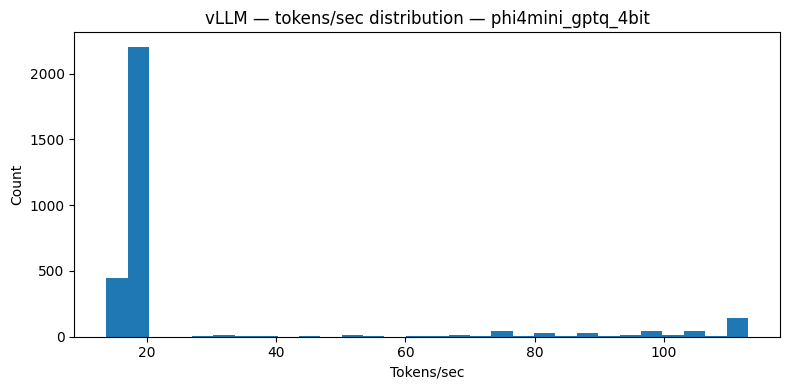

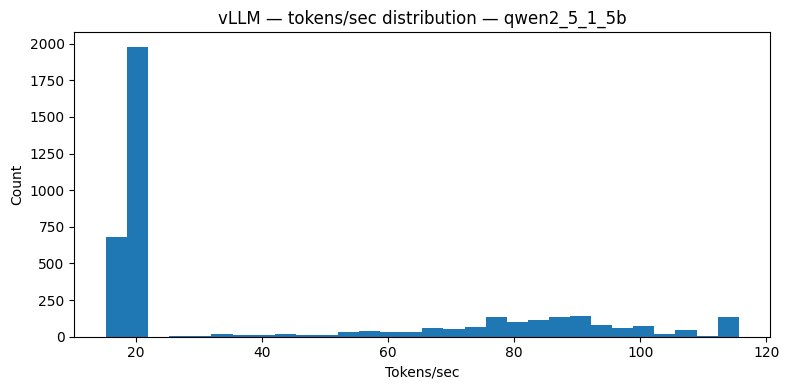

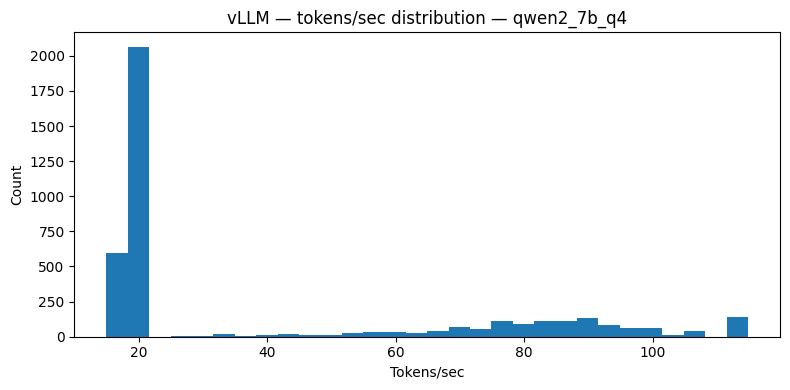

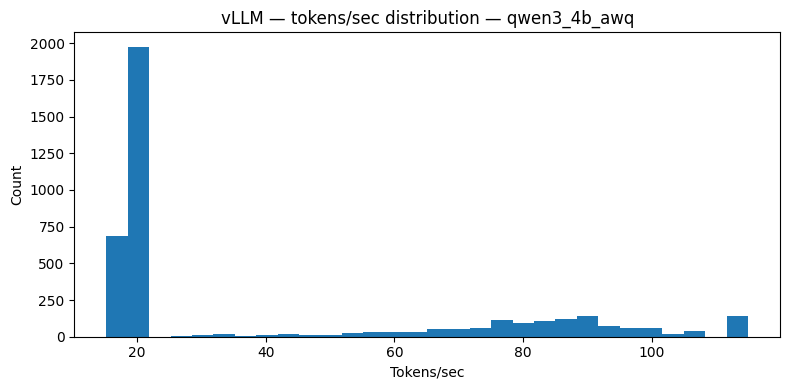

In [45]:
if "tokens_per_sec" in samples.columns:
    for model_name in sorted(samples["model"].dropna().unique()):
        sub = samples[samples["model"] == model_name]["tokens_per_sec"].dropna()

        plt.figure(figsize=(8, 4))
        plt.hist(sub, bins=30)
        plt.xlabel("Tokens/sec")
        plt.ylabel("Count")
        plt.title(f"vLLM — tokens/sec distribution — {model_name}")
        plt.tight_layout()
        safe_name = str(model_name).replace("/", "_")
        plt.savefig(FIGURES_DIR / f"tps_distribution_{safe_name}.png", dpi=200)
        plt.show()


 Sample power distribution by model

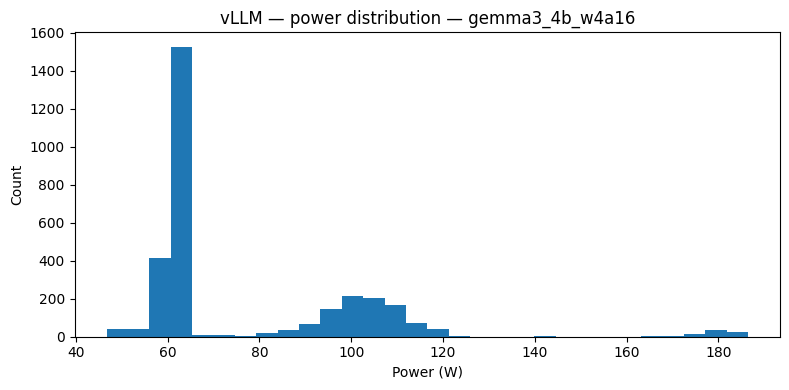

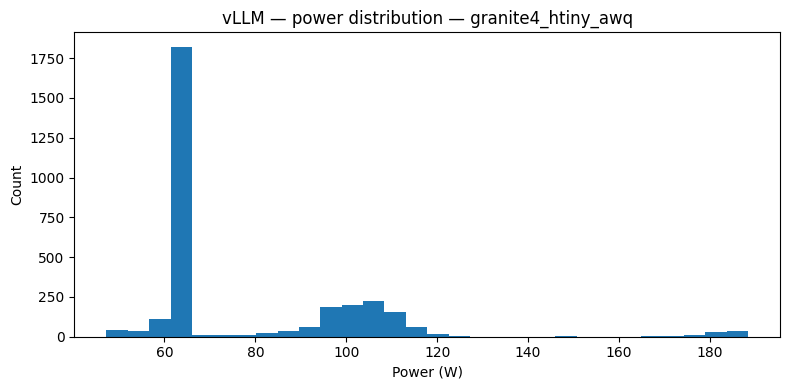

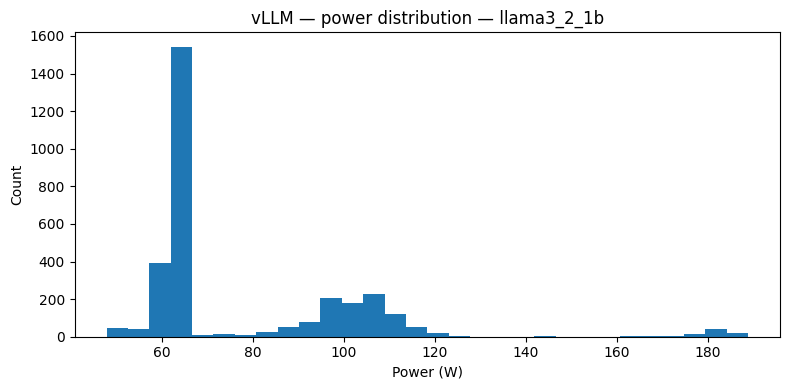

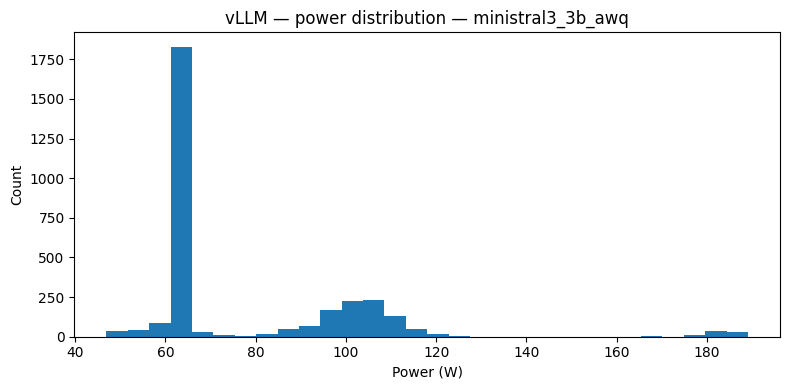

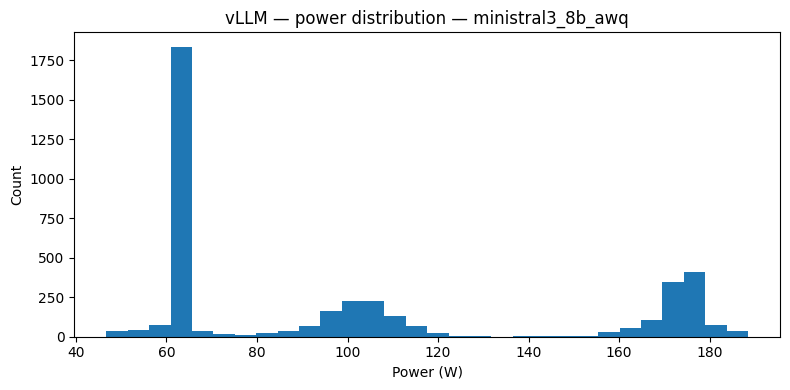

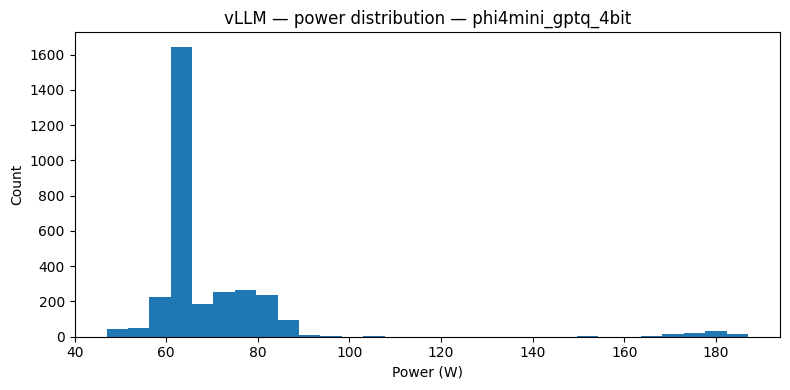

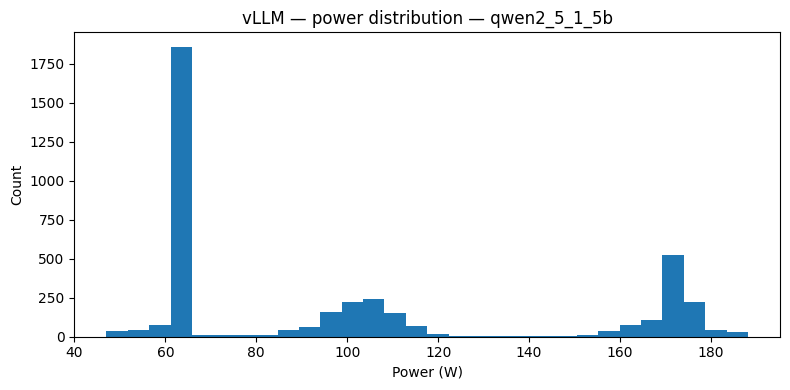

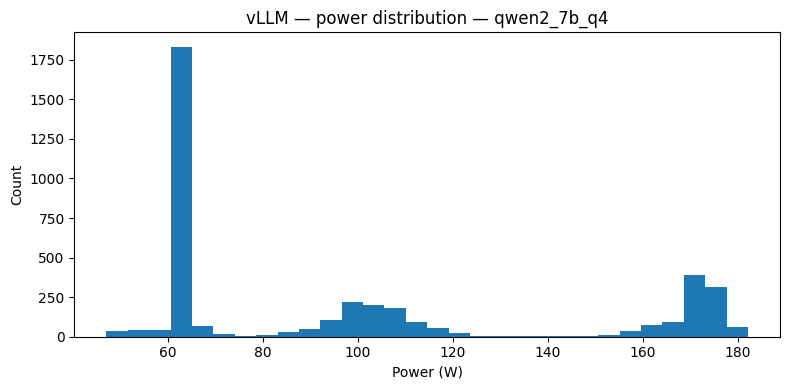

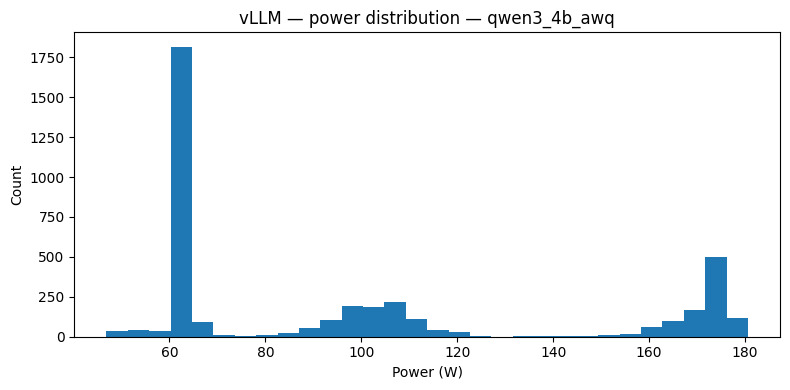

In [46]:
if "power_w_avg" in samples.columns:
    for model_name in sorted(samples["model"].dropna().unique()):
        sub = samples[samples["model"] == model_name]["power_w_avg"].dropna()

        plt.figure(figsize=(8, 4))
        plt.hist(sub, bins=30)
        plt.xlabel("Power (W)")
        plt.ylabel("Count")
        plt.title(f"vLLM — power distribution — {model_name}")
        plt.tight_layout()
        safe_name = str(model_name).replace("/", "_")
        plt.savefig(FIGURES_DIR / f"power_distribution_{safe_name}.png", dpi=200)
        plt.show()


 Ranking previews

In [47]:
display(ranking_accuracy)
display(ranking_efficiency)


,backend,model,n_runs,n_datasets,avg_accuracy,avg_ttft_ms,avg_latency_ms,avg_tps,avg_sustained_tps,avg_cpu,avg_ram_mb,avg_gpu,avg_vram_mb,avg_power_w,avg_tps_per_vram,avg_tps_per_watt,avg_accuracy_per_latency,avg_accuracy_per_vram,avg_accuracy_per_watt
0,vllm,phi4mini_gptq_4bit,1,3,0.27,72.752167,137.666833,26.416900,10.943933,7.186167,1016.476667,15.277333,6664.333333,66.823900,0.003957,0.382358,0.002094,0.000041,0.004294
1,vllm,granite4_htiny_awq,1,3,0.27,69.667400,131.040900,27.734200,11.344933,6.732467,1021.813333,20.150333,6195.666667,75.213667,0.004477,0.354035,0.002219,0.000044,0.004274
2,vllm,qwen2_7b_q4,1,3,0.27,69.679700,131.080133,27.722433,11.343367,6.745267,1021.683333,15.415233,6194.000000,75.208600,0.004476,0.353915,0.002219,0.000044,0.004271
3,vllm,ministral3_8b_awq,1,3,0.27,69.826467,131.393633,27.648500,11.310733,6.758667,1021.966667,16.514900,6210.000000,75.030700,0.004445,0.353840,0.002211,0.000044,0.004287
4,vllm,qwen2_5_1_5b,1,3,0.27,69.573967,130.966800,27.727800,11.369767,6.735733,1021.236667,17.233767,6196.000000,75.293800,0.004476,0.353518,0.002219,0.000044,0.004277
5,vllm,qwen3_4b_awq,1,3,0.27,69.793967,131.292733,27.686533,11.322567,6.750267,1021.440000,15.571667,6195.000000,75.191567,0.004470,0.353427,0.002214,0.000044,0.004274
6,vllm,llama3_2_1b,1,3,0.27,69.863700,131.413967,27.670567,11.306467,6.739733,1020.890000,18.094000,6183.000000,75.192667,0.004476,0.353272,0.002215,0.000044,0.004267
7,vllm,ministral3_3b_awq,1,3,0.27,69.741600,131.283133,27.674500,11.320867,6.754767,1021.083333,20.730000,6209.333333,75.188667,0.004458,0.353252,0.002216,0.000044,0.004274
8,vllm,gemma3_4b_w4a16,1,3,0.27,71.546167,134.882500,27.052200,11.177767,7.312767,1020.010000,19.003900,6592.666667,74.354567,0.004216,0.347271,0.002114,0.000040,0.004369


,backend,model,n_runs,n_datasets,avg_accuracy,avg_ttft_ms,avg_latency_ms,avg_tps,avg_sustained_tps,avg_cpu,avg_ram_mb,avg_gpu,avg_vram_mb,avg_power_w,avg_tps_per_vram,avg_tps_per_watt,avg_accuracy_per_latency,avg_accuracy_per_vram,avg_accuracy_per_watt
0,vllm,phi4mini_gptq_4bit,1,3,0.27,72.752167,137.666833,26.416900,10.943933,7.186167,1016.476667,15.277333,6664.333333,66.823900,0.003957,0.382358,0.002094,0.000041,0.004294
1,vllm,granite4_htiny_awq,1,3,0.27,69.667400,131.040900,27.734200,11.344933,6.732467,1021.813333,20.150333,6195.666667,75.213667,0.004477,0.354035,0.002219,0.000044,0.004274
2,vllm,qwen2_7b_q4,1,3,0.27,69.679700,131.080133,27.722433,11.343367,6.745267,1021.683333,15.415233,6194.000000,75.208600,0.004476,0.353915,0.002219,0.000044,0.004271
3,vllm,ministral3_8b_awq,1,3,0.27,69.826467,131.393633,27.648500,11.310733,6.758667,1021.966667,16.514900,6210.000000,75.030700,0.004445,0.353840,0.002211,0.000044,0.004287
4,vllm,qwen2_5_1_5b,1,3,0.27,69.573967,130.966800,27.727800,11.369767,6.735733,1021.236667,17.233767,6196.000000,75.293800,0.004476,0.353518,0.002219,0.000044,0.004277
5,vllm,qwen3_4b_awq,1,3,0.27,69.793967,131.292733,27.686533,11.322567,6.750267,1021.440000,15.571667,6195.000000,75.191567,0.004470,0.353427,0.002214,0.000044,0.004274
6,vllm,llama3_2_1b,1,3,0.27,69.863700,131.413967,27.670567,11.306467,6.739733,1020.890000,18.094000,6183.000000,75.192667,0.004476,0.353272,0.002215,0.000044,0.004267
7,vllm,ministral3_3b_awq,1,3,0.27,69.741600,131.283133,27.674500,11.320867,6.754767,1021.083333,20.730000,6209.333333,75.188667,0.004458,0.353252,0.002216,0.000044,0.004274
8,vllm,gemma3_4b_w4a16,1,3,0.27,71.546167,134.882500,27.052200,11.177767,7.312767,1020.010000,19.003900,6592.666667,74.354567,0.004216,0.347271,0.002114,0.000040,0.004369


 Top-ranked models by accuracy

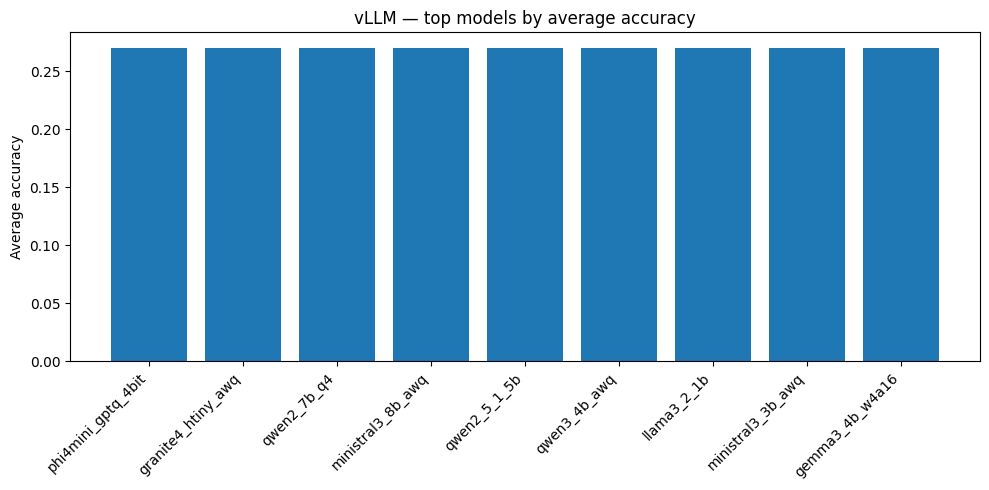

In [48]:
top_acc = ranking_accuracy.head(10).copy()

plt.figure(figsize=(10, 5))
plt.bar(top_acc["model"], top_acc["avg_accuracy"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Average accuracy")
plt.title("vLLM — top models by average accuracy")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "top_ranked_models_accuracy.png", dpi=200)
plt.show()


 Top-ranked models by throughput efficiency

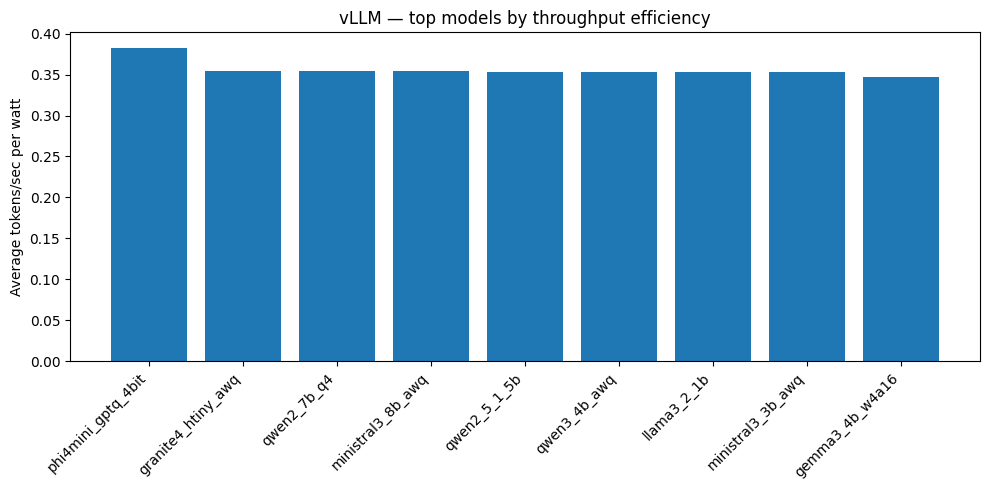

In [49]:
top_eff = ranking_efficiency.head(10).copy()

plt.figure(figsize=(10, 5))
plt.bar(top_eff["model"], top_eff["avg_tps_per_watt"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Average tokens/sec per watt")
plt.title("vLLM — top models by throughput efficiency")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "top_ranked_models_efficiency.png", dpi=200)
plt.show()


 Saved figures

In [50]:
print("Figures saved in:", FIGURES_DIR)
for p in sorted(FIGURES_DIR.glob("*.png")):
    print("-", p.name)

Figures saved in: /home/stephane/resource-efficiency-benchmark/docs/figures/vllm
- accuracy_by_model.png
- accuracy_vs_latency.png
- accuracy_vs_power.png
- accuracy_vs_vram.png
- dolly_latency_by_model.png
- dolly_throughput_by_model.png
- gpu_by_model.png
- gsm8k_accuracy_by_model.png
- gsm8k_latency_by_model.png
- hellaswag_accuracy_by_model.png
- hellaswag_latency_by_model.png
- latency_by_model.png
- latency_distribution_gemma3_4b_w4a16.png
- latency_distribution_granite4_htiny_awq.png
- latency_distribution_llama3_2_1b.png
- latency_distribution_ministral3_3b_awq.png
- latency_distribution_ministral3_8b_awq.png
- latency_distribution_phi4mini_gptq_4bit.png
- latency_distribution_qwen2_5_1_5b.png
- latency_distribution_qwen2_7b_q4.png
- latency_distribution_qwen3_4b_awq.png
- mmlu_accuracy_by_model.png
- mmlu_latency_by_model.png
- power_by_model.png
- power_distribution_gemma3_4b_w4a16.png
- power_distribution_granite4_htiny_awq.png
- power_distribution_llama3_2_1b.png
- power_di